<a href="https://colab.research.google.com/github/prakashrock0510-ni/project-3_hr_job_placement/blob/main/Project_3_analyst_tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(accuracy_score,classification_report,confusion_matrix)

In [ ]:
df=pd.read_csv("/content/Job_placement_cleaneddata.csv")

Test-Train split

In [ ]:
X=df.drop(columns=["status"])
y=df["status"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (40099, 37)
X_test: (10025, 37)
y_train: (40099,)
y_test: (10025,)


Random Forest

In [ ]:
random_forest_model = RandomForestClassifier(n_estimators=100,max_depth=15,random_state=42)
random_forest_model.fit(X_train, y_train)
forest_predictions = random_forest_model.predict(X_test)
print("Random Forest completed")

Random Forest completed


In [ ]:
forest_accuracy = accuracy_score(y_test,forest_predictions)
print("Random Forest Accuracy:", round(forest_accuracy, 4))
print("Accuracy Percentage:", round(forest_accuracy * 100, 2), "%")
print("Random Forest Classification Report")
print(classification_report(y_test,forest_predictions,labels=[0, 1],target_names=["Not Placed", "Placed"],zero_division=0))
forest_cm = confusion_matrix(y_test,forest_predictions,labels=[0, 1])
print("Random Forest Confusion Matrix")
print(forest_cm)

Random Forest Accuracy: 0.8927
Accuracy Percentage: 89.27 %
Random Forest Classification Report
              precision    recall  f1-score   support

  Not Placed       0.90      0.96      0.93      6990
      Placed       0.88      0.75      0.81      3035

    accuracy                           0.89     10025
   macro avg       0.89      0.85      0.87     10025
weighted avg       0.89      0.89      0.89     10025

Random Forest Confusion Matrix
[[6677  313]
 [ 763 2272]]


Analyst Tasks (EDA & ML Analytics)


Candidate Performance Analysis



1.Academic scores vs placement outcome

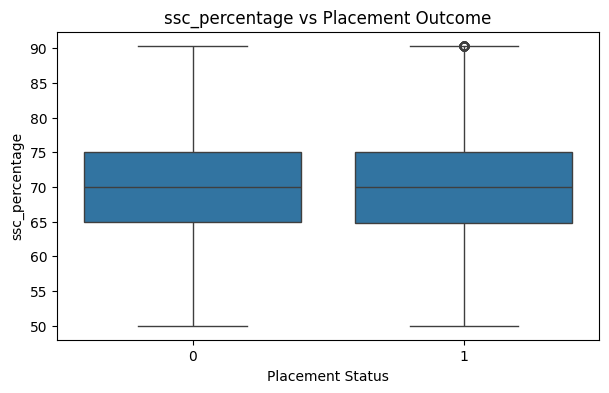

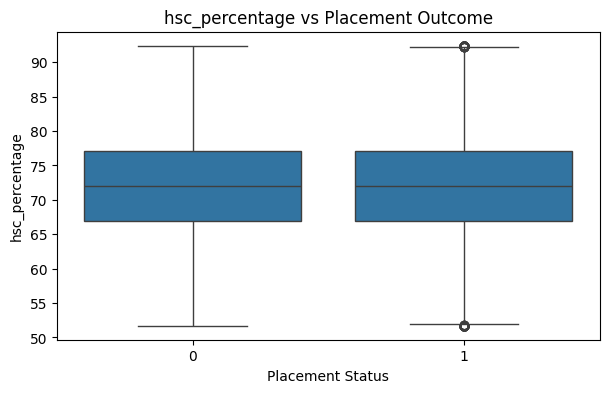

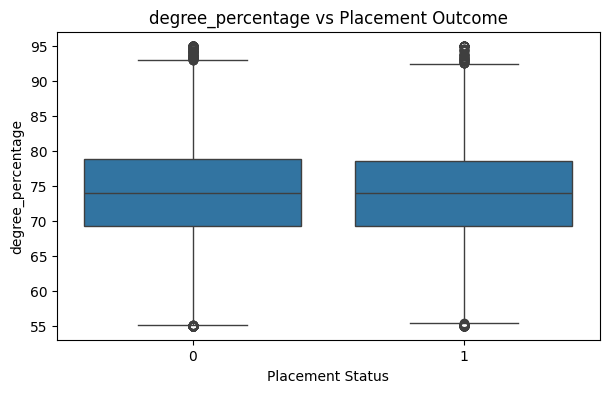

In [ ]:
df["placed_flag"] = df["status"].map({"Not Placed": 0,"Placed": 1})
academic_columns = ["ssc_percentage","hsc_percentage","degree_percentage"]
for column in academic_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df,x="status",y=column)
    plt.title(f"{column} vs Placement Outcome")
    plt.xlabel("Placement Status")
    plt.ylabel(column)
    plt.show()

2.Skills match vs interview performance


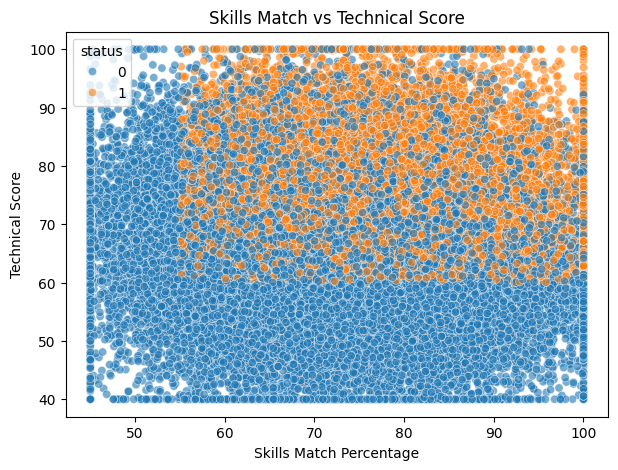

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df,x="skills_match_percentage",y="technical_score",hue="status",alpha=0.6)
plt.title("Skills Match vs Technical Score")
plt.xlabel("Skills Match Percentage")
plt.ylabel("Technical Score")
plt.show()

3.Certification impact on job acceptance

[0 1]
status
0    34950
1    15174
Name: count, dtype: int64


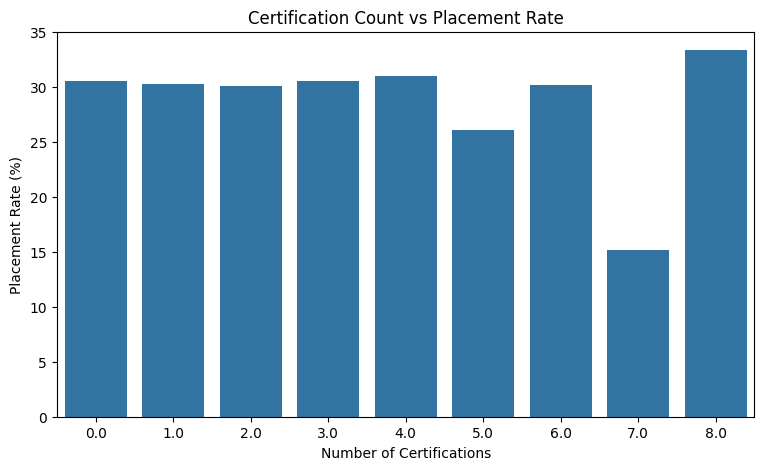

   certifications_count  placement_rate
0                   0.0       30.550837
1                   1.0       30.208333
2                   2.0       30.080831
3                   3.0       30.532461
4                   4.0       30.970337
5                   5.0       26.032316
6                   6.0       30.172414
7                   7.0       15.151515
8                   8.0       33.333333


In [ ]:
print(df["status"].unique())
print(df["status"].value_counts(dropna=False))
placed_candidates = df[df["status"] == 1].groupby("certifications_count").size()
total_candidates = df.groupby("certifications_count").size()
placement_rate = (placed_candidates / total_candidates) * 100
placement_rate = placement_rate.fillna(0)
certification_analysis = placement_rate.reset_index(name="placement_rate")
plt.figure(figsize=(9, 5))
sns.barplot(data=certification_analysis,x="certifications_count",y="placement_rate")
plt.title("Certification Count vs Placement Rate")
plt.xlabel("Number of Certifications")
plt.ylabel("Placement Rate (%)")
plt.show()
print(certification_analysis)


Placement & Acceptance Analysis

4.Acceptance rate by company tier

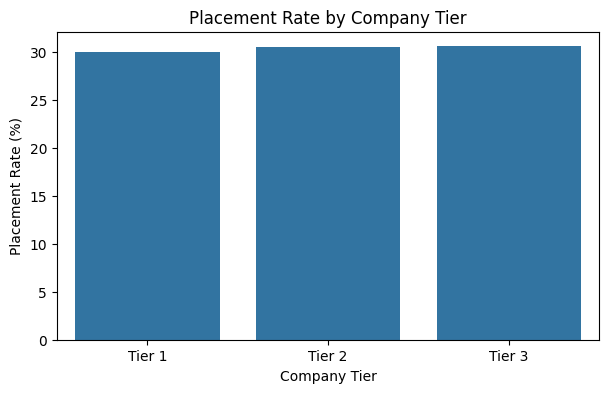

  company_tier  Placement_Rate
0       Tier 1       29.951441
1       Tier 2       30.430560
2       Tier 3       30.542838


In [ ]:
df["company_tier"] = "Tier 1"
df.loc[df["company_tier_Tier 2"] == 1, "company_tier"] = "Tier 2"
df.loc[df["company_tier_Tier 3"] == 1, "company_tier"] = "Tier 3"
tier_analysis = df.groupby("company_tier")["status"].mean() * 100
tier_analysis = tier_analysis.reset_index(name="Placement_Rate")
plt.figure(figsize=(7, 4))
sns.barplot(data=tier_analysis,x="company_tier",y="Placement_Rate")
plt.title("Placement Rate by Company Tier")
plt.xlabel("Company Tier")
plt.ylabel("Placement Rate (%)")
plt.show()
print(tier_analysis)


5.Experience vs placement success

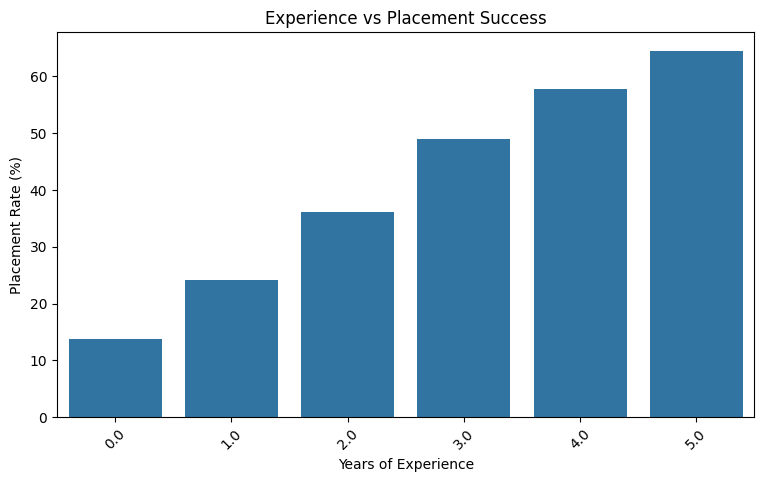

   years_of_experience  Placement_Rate
0                  0.0       13.781602
1                  1.0       24.144810
2                  2.0       36.125288
3                  3.0       49.023497
4                  4.0       57.705287
5                  5.0       64.548495


In [ ]:
experience_analysis = df.groupby("years_of_experience")["status"].mean() * 100
experience_analysis = experience_analysis.reset_index(name="Placement_Rate")
plt.figure(figsize=(9, 5))
sns.barplot(data=experience_analysis,x="years_of_experience",y="Placement_Rate")
plt.title("Experience vs Placement Success")
plt.xlabel("Years of Experience")
plt.ylabel("Placement Rate (%)")
plt.xticks(rotation=45)
plt.show()
print(experience_analysis)


Interview & Evaluation Analysis

6.Interview score vs placement probability

  Score_Group  Placement_Probability
0        0-40                   4.30
1       41-60                   3.99
2       61-80                  36.47
3      81-100                  48.26


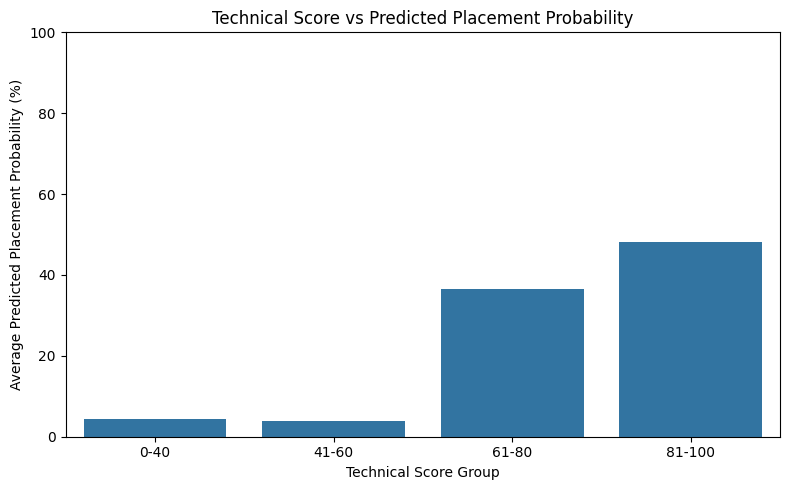

In [ ]:
probabilities = random_forest_model.predict_proba(X_test)
placed_index = list(random_forest_model.classes_).index(1)
placed_probability = probabilities[:, placed_index] * 100
probability_df = pd.DataFrame({"Technical_Score": df.loc[X_test.index, "technical_score"].to_numpy(),"Placement_Probability": placed_probability})
probability_df["Score_Group"] = pd.cut(probability_df["Technical_Score"],bins=[-1, 40, 60, 80, 100],labels=["0-40", "41-60", "61-80", "81-100"],include_lowest=True)
probability_analysis = (probability_df.groupby("Score_Group", observed=False)["Placement_Probability"].mean().reset_index())
print(probability_analysis.round(2))
plt.figure(figsize=(8, 5))
sns.barplot(data=probability_analysis,x="Score_Group",y="Placement_Probability")
plt.title("Technical Score vs Predicted Placement Probability")
plt.xlabel("Technical Score Group")
plt.ylabel("Average Predicted Placement Probability (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


7.Employability test score analysis

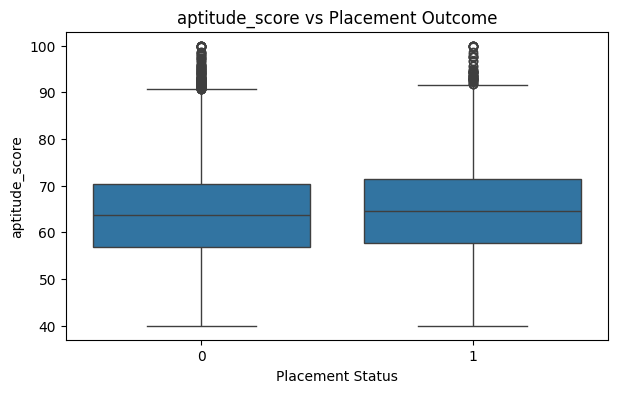

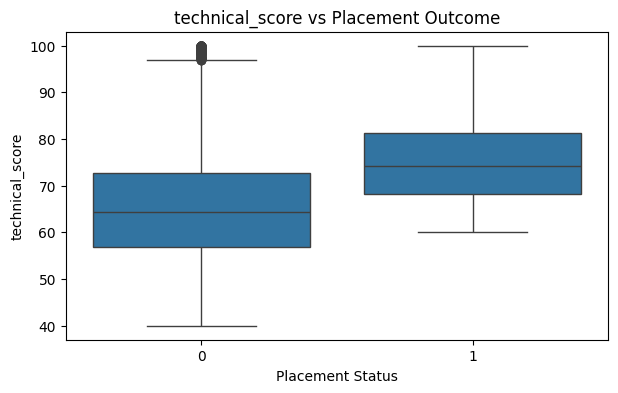

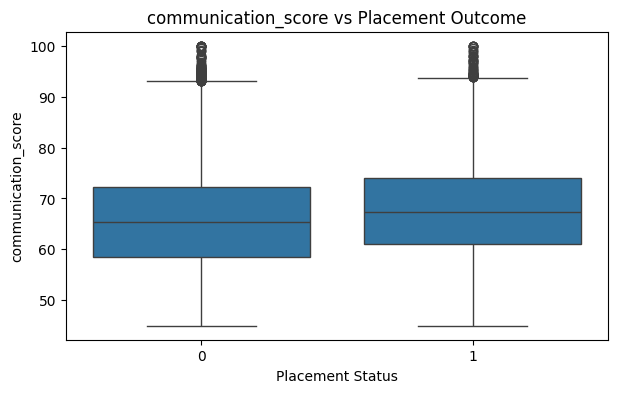

In [ ]:
test_columns = ["aptitude_score","technical_score","communication_score"]
for column in test_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df,x="status",y=column)
    plt.title(f"{column} vs Placement Outcome")
    plt.xlabel("Placement Status")
    plt.ylabel(column)
    plt.show()